# 04 — EV Charging Demand Regression

## Objective
Build and evaluate regression models to predict the recorded `Demand`
target using charging-session, location, and temporal features.

## Experiment Design
We will evaluate two feature configurations using the same chronological
train-test split:

1. **Without Duration:** Uses location, charger company, charger type,
   and temporal features.
2. **With Duration:** Uses the same predictors plus `DurationValidated`.

We will compare Linear Regression, Decision Tree, Random Forest,
Extra Trees, and Histogram Gradient Boosting.

## Evaluation Metrics
- MAE: Mean Absolute Error
- MSE: Mean Squared Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of Determination

## Methodological Notes
- The training data will contain earlier sessions than the test data.
- Missing validated durations will be imputed within the training pipeline.
- Both feature configurations will use the same records and split.
- The physical definition and units of `Demand` are not specified in
  the GUVI project brief.
- Actual session duration is known only after a session ends. Therefore,
  results from the duration-based model must be interpreted as demand
  estimation when duration is available, not automatically as
  session-start forecasting.

In [7]:
from pathlib import Path
import time

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Paths are relative to the notebooks/ directory.
DATA_PATH = Path("../data/processed/ev_charging_features.csv")
REPORTS_DIR = Path("../reports")
MODELS_DIR = Path("../models")

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Check that the expected dataset exists.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

# Load the engineered dataset.
df = pd.read_csv(DATA_PATH)

# Parse the fields used for chronological splitting and regression.
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"],
    errors="coerce",
)

df["Demand"] = pd.to_numeric(
    df["Demand"],
    errors="coerce",
)

df["DurationValidated"] = pd.to_numeric(
    df["DurationValidated"],
    errors="coerce",
)

# Keep company and charger type codes categorical, not continuous numbers.
for col in ["ChargerCompany", "ChargerType"]:
    df[col] = df[col].astype(str)

# Track records excluded because essential target/time data is unavailable.
rows_before = len(df)

df = df.dropna(
    subset=["StartDatetime", "Demand"]
).copy()

rows_removed = rows_before - len(df)

# Sort chronologically for the upcoming time-based split.
df = (
    df.sort_values("StartDatetime")
      .reset_index(drop=True)
)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")
print(f"Rows excluded for missing target/timestamp: {rows_removed}")
print(f"Start date: {df['StartDatetime'].min()}")
print(f"End date: {df['StartDatetime'].max()}")

Dataset loaded successfully.
Dataset shape: (72826, 24)
Rows excluded for missing target/timestamp: 0
Start date: 2021-09-30 17:14:26
End date: 2022-09-30 23:11:59


In [8]:
required_columns = [
    "StartDatetime",
    "Demand",
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
    "DurationValidated",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("Rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing Demand values:", df["Demand"].isna().sum())
print("Missing StartDatetime values:", df["StartDatetime"].isna().sum())

missing_duration = df["DurationValidated"].isna().sum()

print(
    f"Missing validated duration: {missing_duration:,} "
    f"({missing_duration / len(df) * 100:.2f}%)"
)

print("\nDemand summary:")
display(df["Demand"].describe().round(3))

print("\nValidated duration summary:")
display(df["DurationValidated"].describe().round(3))

Rows: 72826
Exact duplicate rows: 0
Missing Demand values: 0
Missing StartDatetime values: 0
Missing validated duration: 3,376 (4.64%)

Demand summary:


count    72826.000
mean        17.440
std         13.491
min          0.010
25%          7.530
50%         14.100
75%         23.200
max         97.000
Name: Demand, dtype: float64


Validated duration summary:


count    69450.000
mean       150.078
std        145.716
min          1.000
25%         40.000
50%        110.000
75%        200.000
max       1573.000
Name: DurationValidated, dtype: float64

In [9]:
# Categorical features shared by both experiments.
categorical_features = [
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
]

# Numeric predictors for the original model.
numeric_features_without_duration = [
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
]

# Add validated duration for the second experiment.
numeric_features_with_duration = (
    numeric_features_without_duration
    + ["DurationValidated"]
)

# Define separate feature matrices.
features_without_duration = (
    categorical_features
    + numeric_features_without_duration
)

features_with_duration = (
    categorical_features
    + numeric_features_with_duration
)

X_without_duration = df[features_without_duration].copy()
X_with_duration = df[features_with_duration].copy()

# Demand is the regression target.
y = df["Demand"].copy()

# Find the approximate 80% chronological boundary.
split_index = int(len(df) * (1 - TEST_SIZE))
split_datetime = df.loc[split_index, "StartDatetime"]

# Keep identical timestamps together in one split.
train_mask = df["StartDatetime"] < split_datetime
test_mask = df["StartDatetime"] >= split_datetime

# Create training and test sets for BOTH experiments.
X_train_without = X_without_duration.loc[train_mask]
X_test_without = X_without_duration.loc[test_mask]

X_train_with = X_with_duration.loc[train_mask]
X_test_with = X_with_duration.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Confirm that both experiments use identical observations.
assert X_train_without.index.equals(X_train_with.index)
assert X_test_without.index.equals(X_test_with.index)
assert y_train.index.equals(X_train_with.index)
assert y_test.index.equals(X_test_with.index)

print("Chronological split completed.")
print(f"Boundary timestamp: {split_datetime}")
print(f"Training rows: {len(X_train_without):,}")
print(f"Testing rows: {len(X_test_without):,}")
print(f"Training percentage: {len(X_train_without) / len(df) * 100:.2f}%")
print(f"Testing percentage: {len(X_test_without) / len(df) * 100:.2f}%")

print("\nTraining date range:")
print(df.loc[train_mask, "StartDatetime"].min())
print(df.loc[train_mask, "StartDatetime"].max())

print("\nTesting date range:")
print(df.loc[test_mask, "StartDatetime"].min())
print(df.loc[test_mask, "StartDatetime"].max())

print("\nMissing duration in training:", X_train_with["DurationValidated"].isna().sum())
print("Missing duration in testing:", X_test_with["DurationValidated"].isna().sum())

Chronological split completed.
Boundary timestamp: 2022-07-30 19:09:37
Training rows: 58,260
Testing rows: 14,566
Training percentage: 80.00%
Testing percentage: 20.00%

Training date range:
2021-09-30 17:14:26
2022-07-30 19:09:27

Testing date range:
2022-07-30 19:09:37
2022-09-30 23:11:59

Missing duration in training: 3042
Missing duration in testing: 334


In [10]:
def make_preprocessor(numeric_features):
    """
    Create preprocessing steps for categorical and numerical features.

    Categorical features:
    - Fill missing values with the most frequent category.
    - Convert categories into one-hot encoded columns.

    Numerical features:
    - Fill missing values with the training-set median.
    - Standardize numerical values.
    """
    categorical_transformer = Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    numeric_transformer = Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_transformer,
                categorical_features,
            ),
            (
                "numeric",
                numeric_transformer,
                numeric_features,
            ),
        ],
        remainder="drop",
    )

    return preprocessor


# Create a separate preprocessing pipeline for each feature set.
preprocessor_without_duration = make_preprocessor(
    numeric_features_without_duration
)

preprocessor_with_duration = make_preprocessor(
    numeric_features_with_duration
)

print("Preprocessing pipelines created.")
print("Features without duration:", features_without_duration)
print("Features with duration:", features_with_duration)

Preprocessing pipelines created.
Features without duration: ['Location', 'ChargerCompany', 'ChargerType', 'StartDayName', 'TimeOfDay', 'StartMonth', 'StartDayOfMonth', 'StartHour', 'IsWeekend']
Features with duration: ['Location', 'ChargerCompany', 'ChargerType', 'StartDayName', 'TimeOfDay', 'StartMonth', 'StartDayOfMonth', 'StartHour', 'IsWeekend', 'DurationValidated']


In [11]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=-1,
    ),
}

print(f"Number of regression models: {len(models)}")
print("Models:", list(models.keys()))

Number of regression models: 5
Models: ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']


In [12]:
# Group both feature configurations for a consistent experiment.
experiments = {
    "Without Duration": {
        "X_train": X_train_without,
        "X_test": X_test_without,
        "numeric_features": numeric_features_without_duration,
    },
    "With Duration": {
        "X_train": X_train_with,
        "X_test": X_test_with,
        "numeric_features": numeric_features_with_duration,
    },
}

results = []
fitted_pipelines = {}
test_predictions = {}

for feature_set, experiment in experiments.items():

    print(f"\nTraining models: {feature_set}")

    for model_name, model in models.items():

        # Build a fresh pipeline so preprocessing is fitted only
        # on this experiment's training data.
        pipeline = Pipeline(steps=[
            (
                "preprocessor",
                make_preprocessor(
                    experiment["numeric_features"]
                ),
            ),
            ("model", clone(model)),
        ])

        start_time = time.perf_counter()

        # Fit the complete preprocessing + modeling pipeline.
        pipeline.fit(
            experiment["X_train"],
            y_train,
        )

        fit_seconds = time.perf_counter() - start_time

        # Evaluate the model on both training and test data.
        train_pred = pipeline.predict(
            experiment["X_train"]
        )

        test_pred = pipeline.predict(
            experiment["X_test"]
        )

        test_mse = mean_squared_error(
            y_test,
            test_pred,
        )

        results.append({
            "FeatureSet": feature_set,
            "Model": model_name,
            "TrainMAE": mean_absolute_error(
                y_train,
                train_pred,
            ),
            "TrainR2": r2_score(
                y_train,
                train_pred,
            ),
            "MAE": mean_absolute_error(
                y_test,
                test_pred,
            ),
            "MSE": test_mse,
            "RMSE": np.sqrt(test_mse),
            "R2": r2_score(
                y_test,
                test_pred,
            ),
            "FitSeconds": fit_seconds,
        })

        # Retain fitted pipelines and predictions for later analysis.
        fitted_pipelines[(feature_set, model_name)] = pipeline
        test_predictions[(feature_set, model_name)] = test_pred

        print(
            f"  {model_name}: "
            f"MAE={mean_absolute_error(y_test, test_pred):.4f}, "
            f"R2={r2_score(y_test, test_pred):.4f}"
        )


# Evaluate a simple baseline that always predicts the training mean.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_without, y_train)

baseline_pred = baseline.predict(X_test_without)
baseline_mse = mean_squared_error(y_test, baseline_pred)

results.append({
    "FeatureSet": "Baseline",
    "Model": "Mean Baseline",
    "TrainMAE": mean_absolute_error(
        y_train,
        baseline.predict(X_train_without),
    ),
    "TrainR2": r2_score(
        y_train,
        baseline.predict(X_train_without),
    ),
    "MAE": mean_absolute_error(y_test, baseline_pred),
    "MSE": baseline_mse,
    "RMSE": np.sqrt(baseline_mse),
    "R2": r2_score(y_test, baseline_pred),
    "FitSeconds": np.nan,
})

results_df = pd.DataFrame(results)

# Show models in ascending order of test MAE.
display(
    results_df
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(4)
)


Training models: Without Duration
  Linear Regression: MAE=10.2516, R2=0.0779
  Decision Tree: MAE=10.3255, R2=0.0406
  Random Forest: MAE=10.2499, R2=0.0602
  XGBoost: MAE=10.5212, R2=0.0768
  LightGBM: MAE=9.9416, R2=0.1212

Training models: With Duration
  Linear Regression: MAE=6.7244, R2=0.3680
  Decision Tree: MAE=4.6044, R2=0.6312
  Random Forest: MAE=4.4579, R2=0.6622
  XGBoost: MAE=4.4796, R2=0.6738
  LightGBM: MAE=4.3466, R2=0.6980


,FeatureSet,Model,TrainMAE,TrainR2,MAE,MSE,RMSE,R2,FitSeconds
0,With Duration,LightGBM,3.5102,0.8022,4.3466,58.4520,7.6454,0.6980,0.4425
1,With Duration,Random Forest,2.0978,0.9190,4.4579,65.3942,8.0867,0.6622,1.3496
2,With Duration,XGBoost,3.4233,0.8088,4.4796,63.1411,7.9461,0.6738,0.4867
3,With Duration,Decision Tree,3.1802,0.8158,4.6044,71.3838,8.4489,0.6312,0.3015
4,With Duration,Linear Regression,5.6426,0.5607,6.7244,122.3368,11.0606,0.3680,0.1644
5,Without Duration,LightGBM,9.0010,0.2022,9.9416,170.1070,13.0425,0.1212,0.4278
6,Without Duration,Random Forest,7.1758,0.4796,10.2499,181.9229,13.4879,0.0602,3.8452
7,Without Duration,Linear Regression,9.7232,0.0891,10.2516,178.5015,13.3604,0.0779,0.4295
8,Without Duration,Decision Tree,8.7802,0.2359,10.3255,185.7176,13.6278,0.0406,0.2361
9,Without Duration,XGBoost,8.8820,0.2216,10.5212,178.7172,13.3685,0.0768,0.5847


In [13]:
# Separate the two feature configurations.
without_duration = (
    results_df[
        results_df["FeatureSet"] == "Without Duration"
    ][["Model", "MAE", "RMSE", "R2"]]
    .rename(columns={
        "MAE": "MAE_WithoutDuration",
        "RMSE": "RMSE_WithoutDuration",
        "R2": "R2_WithoutDuration",
    })
)

with_duration = (
    results_df[
        results_df["FeatureSet"] == "With Duration"
    ][["Model", "MAE", "RMSE", "R2"]]
    .rename(columns={
        "MAE": "MAE_WithDuration",
        "RMSE": "RMSE_WithDuration",
        "R2": "R2_WithDuration",
    })
)

comparison_df = without_duration.merge(
    with_duration,
    on="Model",
    how="inner",
    validate="one_to_one",
)

# Positive values mean test error improved after adding duration.
comparison_df["MAE_Reduction"] = (
    comparison_df["MAE_WithoutDuration"]
    - comparison_df["MAE_WithDuration"]
)

comparison_df["MAE_ReductionPct"] = (
    comparison_df["MAE_Reduction"]
    / comparison_df["MAE_WithoutDuration"]
    * 100
)

comparison_df["R2_Change"] = (
    comparison_df["R2_WithDuration"]
    - comparison_df["R2_WithoutDuration"]
)

display(
    comparison_df
    .sort_values("MAE_WithDuration")
    .reset_index(drop=True)
    .round(4)
)

,Model,MAE_WithoutDuration,RMSE_WithoutDuration,R2_WithoutDuration,MAE_WithDuration,RMSE_WithDuration,R2_WithDuration,MAE_Reduction,MAE_ReductionPct,R2_Change
0,LightGBM,9.9416,13.0425,0.1212,4.3466,7.6454,0.6980,5.5950,56.2787,0.5768
1,Random Forest,10.2499,13.4879,0.0602,4.4579,8.0867,0.6622,5.7919,56.5074,0.6020
2,XGBoost,10.5212,13.3685,0.0768,4.4796,7.9461,0.6738,6.0416,57.4231,0.5971
3,Decision Tree,10.3255,13.6278,0.0406,4.6044,8.4489,0.6312,5.7212,55.4079,0.5906
4,Linear Regression,10.2516,13.3604,0.0779,6.7244,11.0606,0.3680,3.5272,34.4060,0.2901


In [14]:
# Compare training and test performance for every model
# under both feature configurations.

model_diagnostics = results_df[
    results_df["FeatureSet"].isin(
        ["Without Duration", "With Duration"]
    )
][
    [
        "FeatureSet",
        "Model",
        "TrainMAE",
        "MAE",
        "TrainR2",
        "R2",
        "FitSeconds",
    ]
].copy()

# Larger positive gaps may indicate weaker generalization.
model_diagnostics["MAE_Gap"] = (
    model_diagnostics["MAE"]
    - model_diagnostics["TrainMAE"]
)

model_diagnostics["R2_Gap"] = (
    model_diagnostics["TrainR2"]
    - model_diagnostics["R2"]
)

display(
    model_diagnostics
    .sort_values(["FeatureSet", "MAE"])
    .reset_index(drop=True)
    .round(4)
)

,FeatureSet,Model,TrainMAE,MAE,TrainR2,R2,FitSeconds,MAE_Gap,R2_Gap
0,With Duration,LightGBM,3.5102,4.3466,0.8022,0.6980,0.4425,0.8363,0.1042
1,With Duration,Random Forest,2.0978,4.4579,0.9190,0.6622,1.3496,2.3602,0.2568
2,With Duration,XGBoost,3.4233,4.4796,0.8088,0.6738,0.4867,1.0564,0.1350
3,With Duration,Decision Tree,3.1802,4.6044,0.8158,0.6312,0.3015,1.4242,0.1846
4,With Duration,Linear Regression,5.6426,6.7244,0.5607,0.3680,0.1644,1.0818,0.1927
5,Without Duration,LightGBM,9.0010,9.9416,0.2022,0.1212,0.4278,0.9406,0.0810
6,Without Duration,Random Forest,7.1758,10.2499,0.4796,0.0602,3.8452,3.0741,0.4194
7,Without Duration,Linear Regression,9.7232,10.2516,0.0891,0.0779,0.4295,0.5285,0.0113
8,Without Duration,Decision Tree,8.7802,10.3255,0.2359,0.0406,0.2361,1.5453,0.1953
9,Without Duration,XGBoost,8.8820,10.5212,0.2216,0.0768,0.5847,1.6392,0.1449


In [17]:
import joblib
from pathlib import Path

# Create output folders if they do not exist.
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Retrieve the LightGBM pipelines that were already fitted in Cell 7.
lgbm_with_duration = fitted_pipelines[
    ("With Duration", "LightGBM")
]

lgbm_without_duration = fitted_pipelines[
    ("Without Duration", "LightGBM")
]

# Save both models for the two dashboard prediction scenarios.
joblib.dump(
    lgbm_with_duration,
    MODELS_DIR / "lightgbm_with_duration_pipeline.joblib",
)

joblib.dump(
    lgbm_without_duration,
    MODELS_DIR / "lightgbm_without_duration_pipeline.joblib",
)

# Save the existing evaluation tables.
results_df.to_csv(
    REPORTS_DIR / "regression_model_comparison_chronological.csv",
    index=False,
)

comparison_df.to_csv(
    REPORTS_DIR / "regression_duration_feature_comparison.csv",
    index=False,
)

model_diagnostics.to_csv(
    REPORTS_DIR / "regression_model_diagnostics.csv",
    index=False,
)

# Save actual values and predictions from the chronological test set.
prediction_df = pd.DataFrame({
    "StartDatetime": df.loc[
        test_mask, "StartDatetime"
    ].to_numpy(),

    "ActualDemand": y_test.to_numpy(),

    "LightGBM_WithDuration": test_predictions[
        ("With Duration", "LightGBM")
    ],

    "LightGBM_WithoutDuration": test_predictions[
        ("Without Duration", "LightGBM")
    ],
})

prediction_df.to_csv(
    REPORTS_DIR / "regression_test_predictions.csv",
    index=False,
)

# Verify that the artifacts were created and are non-empty.
saved_files = [
    MODELS_DIR / "lightgbm_with_duration_pipeline.joblib",
    MODELS_DIR / "lightgbm_without_duration_pipeline.joblib",
    REPORTS_DIR / "regression_model_comparison_chronological.csv",
    REPORTS_DIR / "regression_duration_feature_comparison.csv",
    REPORTS_DIR / "regression_model_diagnostics.csv",
    REPORTS_DIR / "regression_test_predictions.csv",
]

for file_path in saved_files:
    if not file_path.exists() or file_path.stat().st_size == 0:
        raise RuntimeError(f"Artifact missing or empty: {file_path}")

    print(f"Verified: {file_path.resolve()}")

print("\nRegression artifacts saved and verified.")

Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\models\lightgbm_with_duration_pipeline.joblib
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\models\lightgbm_without_duration_pipeline.joblib
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\regression_model_comparison_chronological.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\regression_duration_feature_comparison.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\regression_model_diagnostics.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\regression_test_predictions.csv

Regression artifacts saved and verified.


# Regression — Summary, Results, and Conclusions

## 1. Objective

The objective of this section was to build machine-learning regression models to predict the recorded `Demand` target using EV charging-session, location, charger, and temporal features.

The experiment also investigated whether adding `DurationValidated` improved demand estimation. Two feature configurations were evaluated: one without duration and one with duration.

The GUVI project brief identifies `Demand` as the regression target, but does not specify its exact physical definition or units. Therefore, all errors and predictions are expressed in the dataset's recorded target units.

## 2. Dataset and preparation

The regression notebook used the feature-engineered dataset:

`data/processed/ev_charging_features.csv`

| Dataset check | Observed result |
|---|---:|
| Total records | 72,826 |
| Total columns | 24 |
| Exact duplicate rows | 0 |
| Missing `Demand` values | 0 |
| Missing `StartDatetime` values | 0 |
| Missing `DurationValidated` values | 3,376 (4.64%) |
| Start timestamp coverage | 2021-09-30 to 2022-09-30 |

No records needed to be excluded for a missing target or timestamp in this notebook. Records with missing validated duration were retained and handled by the preprocessing pipeline.

`DurationValidated` was created during data cleaning by accepting only positive durations that agreed with timestamp-derived elapsed minutes within a project-defined tolerance of two minutes. The source metadata did not independently confirm the original duration unit.

## 3. Feature configurations

Two feature configurations were compared.

### Configuration A — Without Duration

**Categorical predictors**
- `Location`
- `ChargerCompany`
- `ChargerType`
- `StartDayName`
- `TimeOfDay`

**Numerical predictors**
- `StartMonth`
- `StartDayOfMonth`
- `StartHour`
- `IsWeekend`

### Configuration B — With Duration

This configuration uses all the predictors above and adds:

- `DurationValidated`

The company and charger type codes were explicitly converted to strings so they would be treated as categorical values rather than continuous numerical measurements.

`Demand` was used only as the regression target. `DemandCategory` was not used as a predictor. User and charger identifiers were excluded to reduce the risk of identifier memorization. Raw duration, end timestamps, and other end-of-session fields were excluded from the shared feature set.

## 4. Chronological train-test split

The observations were sorted by `StartDatetime`, and an approximately 80/20 chronological split was created.

| Split detail | Result |
|---|---|
| Training records | 58,260 |
| Testing records | 14,566 |
| Training period | 2021-09-30 17:14:26 to 2022-07-30 19:09:27 |
| Testing period | 2022-07-30 19:09:37 to 2022-09-30 23:11:59 |
| Split boundary | 2022-07-30 19:09:37 |

Both feature configurations used the same training and test records. Records at the boundary timestamp were kept together in the test set.

A chronological split was selected because it evaluates performance on later observations instead of randomly mixing earlier and later sessions.

## 5. Preprocessing and model development

Preprocessing was implemented using scikit-learn `Pipeline` and `ColumnTransformer` components.

- **Categorical features:** missing-value imputation with the most frequent category, followed by one-hot encoding with `handle_unknown="ignore"`.
- **Numerical features:** median imputation followed by standardization.
- **Missing duration:** median-imputed within the fitted training pipeline; records were not removed solely because duration was missing.
- **Evaluation:** MAE, MSE, RMSE, and R² were calculated for the regression models.

The following five algorithms were compared:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. XGBoost Regressor
5. LightGBM Regressor

The initial model configurations were evaluated without a separate hyperparameter-tuning search. The decision was made to prioritize a complete, reproducible project and the Streamlit application.

## 6. Test-set model comparison

### Results without and with validated duration

| Model | MAE without duration | RMSE without duration | R² without duration | MAE with duration | RMSE with duration | R² with duration |
|---|---:|---:|---:|---:|---:|---:|
| **LightGBM** | 9.9416 | 13.0425 | 0.1212 | **4.3466** | **7.6454** | **0.6980** |
| Random Forest | 10.2499 | 13.4879 | 0.0602 | 4.4579 | 8.0867 | 0.6622 |
| XGBoost | 10.5212 | 13.3685 | 0.0768 | 4.4796 | 7.9461 | 0.6738 |
| Decision Tree | 10.3255 | 13.6278 | 0.0406 | 4.6044 | 8.4489 | 0.6312 |
| Linear Regression | 10.2516 | 13.3604 | 0.0779 | 6.7244 | 11.0606 | 0.3680 |

The complete evaluation output, including MSE and fitting time, was saved in `reports/regression_model_comparison_chronological.csv`.

Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates that more variation in the target is explained by the model on the evaluation set.

### Key findings

1. LightGBM achieved the strongest overall test performance in both feature configurations.
2. Without duration, LightGBM achieved an MAE of 9.9416, RMSE of 13.0425, and R² of 0.1212.
3. With duration, LightGBM achieved an MAE of 4.3466, RMSE of 7.6454, and R² of 0.6980.
4. Adding duration reduced LightGBM's test MAE by approximately **56.28%** relative to its version without duration.
5. The duration-informed configuration improved test MAE across all five algorithms. The percentage reductions ranged from approximately 34.41% for Linear Regression to 57.42% for XGBoost.
6. Random Forest and XGBoost also performed competitively with duration, but neither surpassed LightGBM on all three reported test metrics.

These results indicate that validated duration contains substantial predictive information about the recorded `Demand` target in this dataset.

## 7. Training-versus-test diagnostics

The training and test metrics were compared to evaluate whether models fit the training data substantially better than later observations.

| Model with duration | Training MAE | Test MAE | Training R² | Test R² | MAE gap | R² gap |
|---|---:|---:|---:|---:|---:|---:|
| **LightGBM** | 3.5102 | 4.3466 | 0.8022 | 0.6980 | **0.8363** | **0.1042** |
| Random Forest | 2.0978 | 4.4579 | 0.9190 | 0.6622 | 2.3602 | 0.2568 |
| XGBoost | 3.4233 | 4.4796 | 0.8088 | 0.6738 | 1.0564 | 0.1350 |
| Decision Tree | 3.1802 | 4.6044 | 0.8158 | 0.6312 | 1.4242 | 0.1846 |
| Linear Regression | 5.6426 | 6.7244 | 0.5607 | 0.3680 | 1.0818 | 0.1927 |

The MAE gap is the test MAE minus the training MAE. The R² gap is the training R² minus the test R².

LightGBM had a smaller training-test gap than the other models with duration in this experiment. Random Forest had the strongest training fit among those models but a larger generalization gap. These diagnostics support keeping LightGBM as the leading candidate, but they do not establish performance under every future period or operating condition.

## 8. Model selection

**Selected leading candidate: LightGBM with `DurationValidated`.**

The reasons for selecting it are:

- Lowest test MAE and RMSE among the five models with duration.
- Highest test R² in the same comparison.
- Smaller training-test gap than the other duration-informed models in this experiment.
- A fitted preprocessing-and-model pipeline can be saved and reused by the Streamlit application without retraining at inference time.

LightGBM without duration is retained as a comparison pipeline for predictions where duration is unavailable.

No additional hyperparameter tuning was performed because the project priority shifted to completing the end-to-end dashboard.

## 9. Saved artifacts

The following files were saved and their existence and non-zero file sizes were verified.

**Model pipelines**
- `models/lightgbm_with_duration_pipeline.joblib`
- `models/lightgbm_without_duration_pipeline.joblib`

**Evaluation reports**
- `reports/regression_model_comparison_chronological.csv`
- `reports/regression_duration_feature_comparison.csv`
- `reports/regression_model_diagnostics.csv`
- `reports/regression_test_predictions.csv`

The saved pipelines include the preprocessing steps and fitted LightGBM estimator. The feature-building logic for user-entered dates and times still needs to be implemented and tested in the application.

## 10. Limitations and interpretation

### Target definition

The GUVI project brief does not identify the exact physical meaning or units of `Demand`. The project therefore does not label predictions as kW, kWh, or any other physical unit without supporting metadata.

### Duration availability

Actual session duration is only known when the session has ended. Including `DurationValidated` creates a substantial improvement in retrospective or duration-informed estimation, but the resulting scores cannot be interpreted as equivalent performance for predicting demand before a session starts.

If the Streamlit dashboard asks for an estimated duration, it must clearly label that value as a user-supplied estimate rather than an observed and validated duration. The performance of this usage scenario has not been independently evaluated.

### Evaluation scope

The results come from one chronological holdout test set. They may not generalize to every location, charger, future time period, or operating condition. Model associations and predictive performance do not establish causal relationships.

### Hyperparameter search

The results are from the selected initial configurations. They are not the outcome of an exhaustive or randomized hyperparameter-optimization process.

## 11. Conclusion and next steps

The regression experiment compared five algorithms under two feature configurations using consistent chronological evaluation. LightGBM with validated duration was the leading candidate, achieving a test MAE of 4.3466, RMSE of 7.6454, and R² of 0.6980.

The results also showed that the duration-free model performed substantially worse, reinforcing that the prediction scenario and the availability of input features must be made explicit.

The regression artifacts have been saved and verified. The next project section is **Notebook 05 — High-Demand Classification**, followed by time-series forecasting and completion of the Streamlit dashboard. The dashboard will use manual form inputs rather than CSV uploads and will load saved pipelines rather than retraining models within the application.

## Model Explainability — Regression

### Objective
Understand which input features have the greatest influence on the predictions produced by our trained LightGBM regression models.

### Method: Permutation Feature Importance
Permutation importance measures how much a model's evaluation score deteriorates when the values of one feature are randomly shuffled. Features whose permutation substantially worsens the score are more useful to the model under the evaluation setup.

We will calculate permutation importance on the chronological test set using MAE-based scoring for both LightGBM configurations:
- With `DurationValidated`
- Without `DurationValidated`

This comparison helps distinguish the influence of duration from the contribution of location, charger, and temporal features.

Permutation importance describes predictive usefulness for this fitted model and test set. It does not establish causation, and correlated features can share or obscure importance.


Calculating importance: With Duration


,Feature,ImportanceMean,ImportanceStd
0,DurationValidated,10.0224,0.1093
1,ChargerType,4.1343,0.0509
2,ChargerCompany,0.5241,0.0088
3,Location,0.3565,0.0141
4,StartHour,0.1292,0.0061
5,TimeOfDay,0.0096,0.0027
6,IsWeekend,0.0033,0.0016
7,StartDayName,0.0023,0.0022
8,StartMonth,-0.0013,0.0024
9,StartDayOfMonth,-0.0086,0.0036


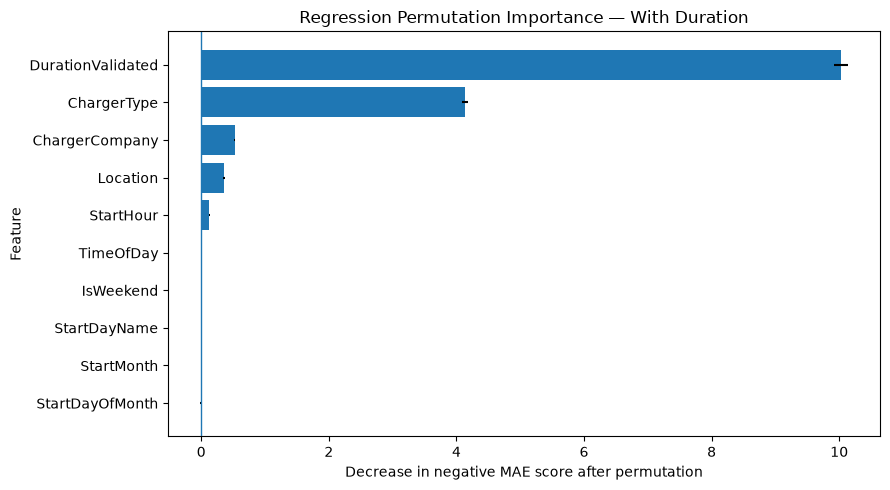


Calculating importance: Without Duration


,Feature,ImportanceMean,ImportanceStd
0,ChargerType,0.7157,0.0271
1,StartHour,0.5939,0.0328
2,Location,0.4051,0.0150
3,ChargerCompany,0.1858,0.0145
4,TimeOfDay,0.0926,0.0070
5,IsWeekend,0.0091,0.0024
6,StartDayName,0.0072,0.0026
7,StartDayOfMonth,0.0062,0.0034
8,StartMonth,0.0004,0.0017


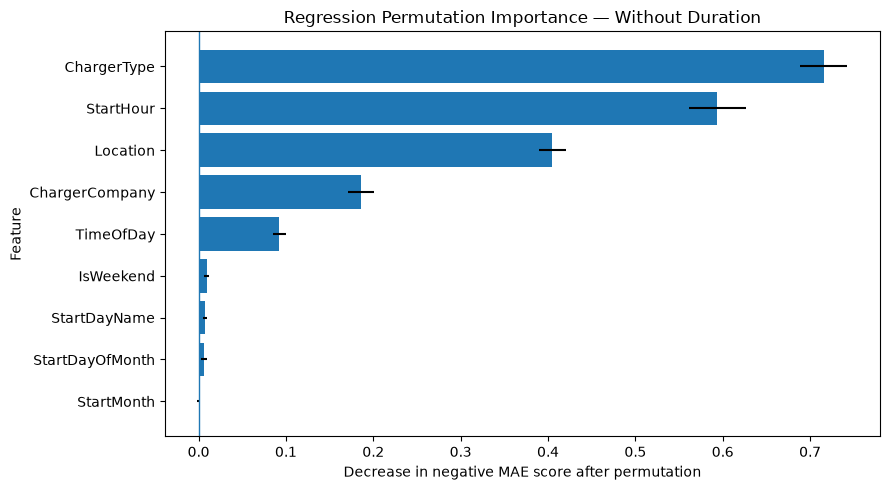


Permutation importance calculations completed.


In [18]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Reuse the same chronological test data from regression.
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the previously trained LightGBM pipelines.
lgbm_with_duration = joblib.load(
    MODELS_DIR / "lightgbm_with_duration_pipeline.joblib"
)

lgbm_without_duration = joblib.load(
    MODELS_DIR / "lightgbm_without_duration_pipeline.joblib"
)

# Pair each model with the feature matrix it expects.
explainability_experiments = {
    "With Duration": (
        lgbm_with_duration,
        X_test_with,
    ),
    "Without Duration": (
        lgbm_without_duration,
        X_test_without,
    ),
}

importance_tables = {}

for experiment_name, (pipeline, X_test_current) in (
    explainability_experiments.items()
):
    print(f"\nCalculating importance: {experiment_name}")

    # Permute one input feature at a time and measure the
    # deterioration in negative MAE score.
    importance = permutation_importance(
        estimator=pipeline,
        X=X_test_current,
        y=y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    # Since the score is negative MAE, a positive importance
    # means shuffling the feature worsened prediction performance.
    importance_df = pd.DataFrame({
        "Feature": X_test_current.columns,
        "ImportanceMean": importance.importances_mean,
        "ImportanceStd": importance.importances_std,
    }).sort_values(
        "ImportanceMean",
        ascending=False,
    ).reset_index(drop=True)

    importance_tables[experiment_name] = importance_df

    # Save the numerical results for reproducibility.
    filename = (
        "regression_permutation_importance_"
        + experiment_name.lower().replace(" ", "_")
        + ".csv"
    )

    importance_df.to_csv(
        REPORTS_DIR / filename,
        index=False,
    )

    display(importance_df.round(4))

    # Plot the feature importance ranking.
    plot_df = importance_df.sort_values(
        "ImportanceMean",
        ascending=True,
    )

    plt.figure(figsize=(9, 5))
    plt.barh(
        plot_df["Feature"],
        plot_df["ImportanceMean"],
        xerr=plot_df["ImportanceStd"],
    )
    plt.axvline(0, linewidth=1)
    plt.title(
        f"Regression Permutation Importance — {experiment_name}"
    )
    plt.xlabel("Decrease in negative MAE score after permutation")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

print("\nPermutation importance calculations completed.")

In [19]:
# Define the categorical features shared by both experiments.
categorical_features = [
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
]

# Numerical predictors for the model without duration.
numeric_features_without_duration = [
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
]

# The second experiment adds validated duration.
numeric_features_with_duration = (
    numeric_features_without_duration
    + ["DurationValidated"]
)

# Define the two feature configurations.
features_without_duration = (
    categorical_features
    + numeric_features_without_duration
)

features_with_duration = (
    categorical_features
    + numeric_features_with_duration
)

# Sort sessions chronologically before splitting.
df = (
    df.sort_values("StartDatetime")
      .reset_index(drop=True)
)

# Encode classes as integers for compatibility across classifiers:
# 0 = Normal Demand, 1 = High Demand.
target_mapping = {
    "Normal Demand": 0,
    "High Demand": 1,
}

y = df["DemandCategory"].map(target_mapping)

if y.isna().any():
    raise ValueError("Unexpected or missing classification labels.")

y = y.astype(int)

# Build the two feature matrices.
X_without_duration = df[features_without_duration].copy()
X_with_duration = df[features_with_duration].copy()

# Use the same approximate 80/20 chronological boundary as regression.
split_index = int(len(df) * (1 - TEST_SIZE))
split_datetime = df.loc[split_index, "StartDatetime"]

# Keep all records with the same boundary timestamp in one split.
train_mask = df["StartDatetime"] < split_datetime
test_mask = df["StartDatetime"] >= split_datetime

X_train_without = X_without_duration.loc[train_mask]
X_test_without = X_without_duration.loc[test_mask]

X_train_with = X_with_duration.loc[train_mask]
X_test_with = X_with_duration.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Verify both experiments use identical observations.
assert X_train_without.index.equals(X_train_with.index)
assert X_test_without.index.equals(X_test_with.index)
assert y_train.index.equals(X_train_with.index)
assert y_test.index.equals(X_test_with.index)

print("Chronological split completed.")
print(f"Boundary timestamp: {split_datetime}")
print(f"Training rows: {len(y_train):,}")
print(f"Testing rows: {len(y_test):,}")

print("\nTraining period:")
print(df.loc[train_mask, "StartDatetime"].min())
print(df.loc[train_mask, "StartDatetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "StartDatetime"].min())
print(df.loc[test_mask, "StartDatetime"].max())

# Inspect the class balance separately in each period.
class_names = {
    0: "Normal Demand",
    1: "High Demand",
}

for split_name, labels in [
    ("Training", y_train),
    ("Testing", y_test),
]:
    counts = labels.map(class_names).value_counts()
    percentages = (
        labels.map(class_names)
        .value_counts(normalize=True)
        .mul(100)
    )

    print(f"\n{split_name} class distribution:")

    display(pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2),
    }))

Chronological split completed.
Boundary timestamp: 2022-07-30 19:09:37
Training rows: 58,260
Testing rows: 14,566

Training period:
2021-09-30 17:14:26
2022-07-30 19:09:27

Testing period:
2022-07-30 19:09:37
2022-09-30 23:11:59

Training class distribution:


,Count,Percentage
DemandCategory,,
High Demand,29302,50.3
Normal Demand,28958,49.7



Testing class distribution:


,Count,Percentage
DemandCategory,,
Normal Demand,7429,51.0
High Demand,7137,49.0



SHAP analysis: Without Duration


,Feature,MeanAbsoluteSHAP
0,numeric__StartHour,2.5921
1,categorical__ChargerType_0,1.4613
2,categorical__ChargerCompany_0,0.8475
3,categorical__TimeOfDay_Evening,0.6036
4,categorical__Location_hotel,0.4342
5,categorical__Location_apartment,0.4265
6,numeric__StartMonth,0.3604
7,categorical__Location_camping,0.2575
8,numeric__StartDayOfMonth,0.2416
9,categorical__ChargerType_1,0.2372


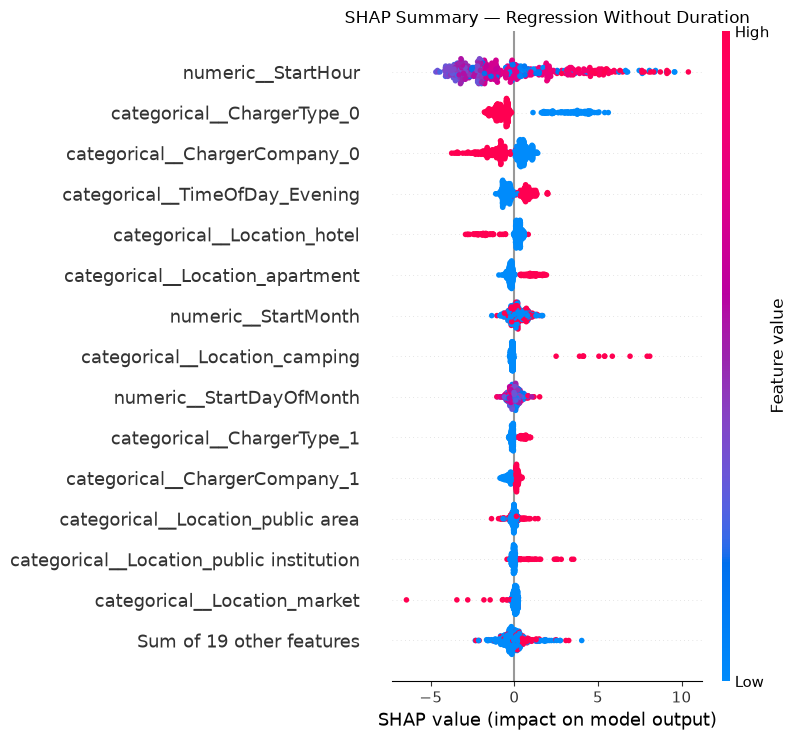

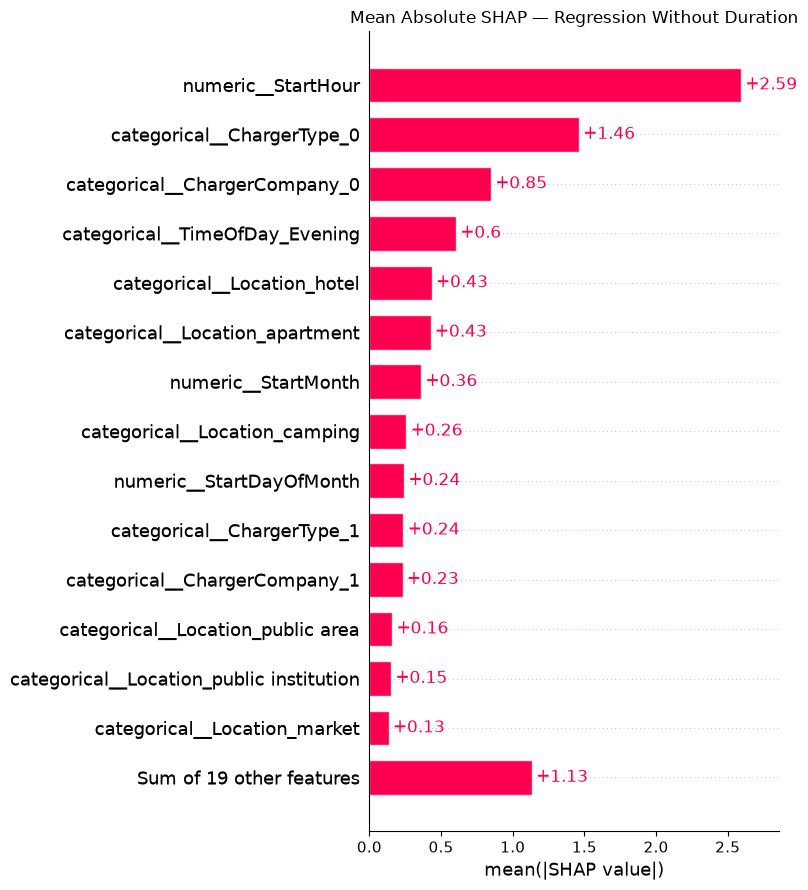


SHAP analysis: With Duration


,Feature,MeanAbsoluteSHAP
0,numeric__DurationValidated,7.9578
1,categorical__ChargerType_0,2.9085
2,categorical__ChargerType_1,1.2176
3,categorical__ChargerCompany_0,0.7258
4,numeric__StartHour,0.4947
5,numeric__StartMonth,0.4121
6,categorical__Location_apartment,0.2115
7,categorical__ChargerCompany_1,0.1565
8,categorical__TimeOfDay_Evening,0.1536
9,categorical__Location_hotel,0.1316


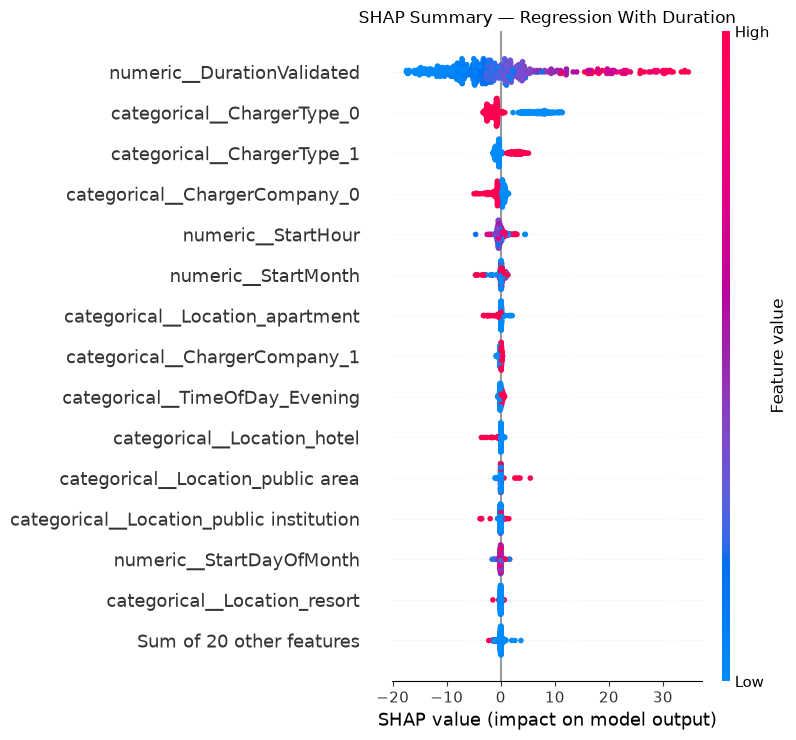

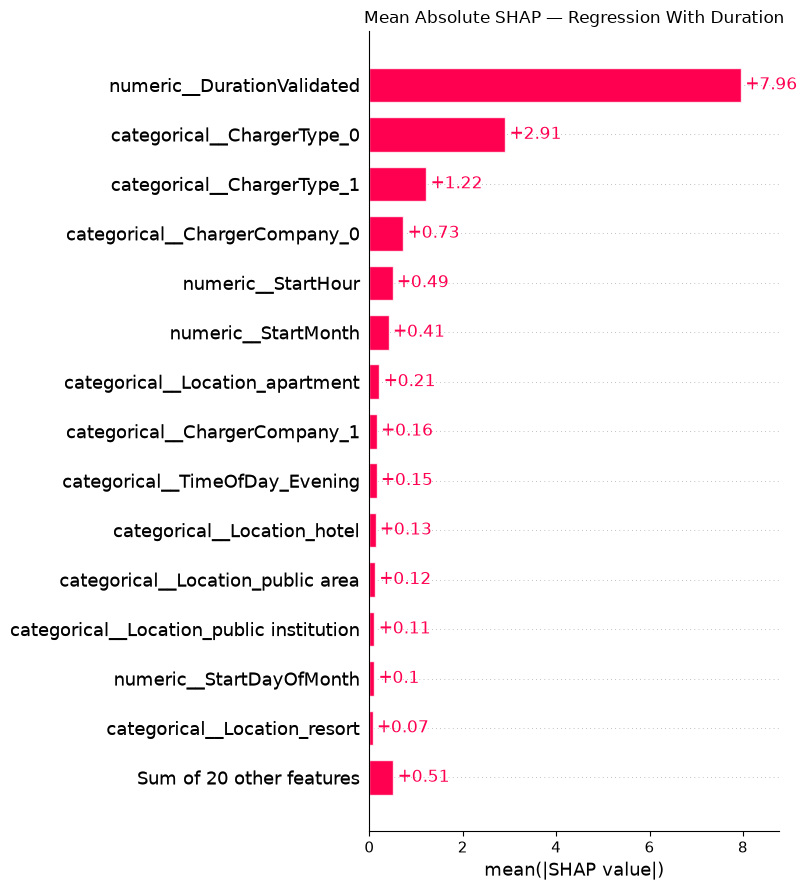


Regression SHAP explanations completed.


In [20]:
import shap
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the existing fitted regression pipelines.
shap_models = {
    "Without Duration": (
        joblib.load(
            MODELS_DIR / "lightgbm_without_duration_pipeline.joblib"
        ),
        X_test_without,
    ),
    "With Duration": (
        joblib.load(
            MODELS_DIR / "lightgbm_with_duration_pipeline.joblib"
        ),
        X_test_with,
    ),
}

for experiment_name, (pipeline, X_test_current) in shap_models.items():
    print(f"\nSHAP analysis: {experiment_name}")

    # Separate preprocessing from the fitted LightGBM estimator.
    preprocessor = pipeline.named_steps["preprocessor"]
    model = pipeline.named_steps["model"]

    # Transform inputs using the preprocessing fitted during training.
    transformed = preprocessor.transform(X_test_current)
    feature_names = preprocessor.get_feature_names_out()

    transformed_df = pd.DataFrame(
        transformed,
        columns=feature_names,
        index=X_test_current.index,
    )

    # Use a reproducible sample to keep execution practical.
    shap_sample = transformed_df.sample(
        n=min(500, len(transformed_df)),
        random_state=42,
    )

    # Explain the trained LightGBM model.
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(shap_sample)

    # Global importance: average absolute SHAP contribution.
    shap_importance_df = pd.DataFrame({
        "Feature": shap_sample.columns,
        "MeanAbsoluteSHAP": np.abs(shap_values.values).mean(axis=0),
    }).sort_values(
        "MeanAbsoluteSHAP",
        ascending=False,
    ).reset_index(drop=True)

    display(shap_importance_df.head(15).round(4))

    # Save the numerical importance results.
    suffix = experiment_name.lower().replace(" ", "_")

    shap_importance_df.to_csv(
        REPORTS_DIR / f"regression_shap_importance_{suffix}.csv",
        index=False,
    )

    # SHAP global summary plot.
    shap.plots.beeswarm(
        shap_values,
        max_display=15,
        show=False,
    )
    plt.title(f"SHAP Summary — Regression {experiment_name}")
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f"regression_shap_summary_{suffix}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    # SHAP global bar plot.
    shap.plots.bar(
        shap_values,
        max_display=15,
        show=False,
    )
    plt.title(f"Mean Absolute SHAP — Regression {experiment_name}")
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f"regression_shap_bar_{suffix}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

print("\nRegression SHAP explanations completed.")

## Findings: SHAP Explainability — Regression

### Objective
SHAP was used to examine how individual input features contribute to LightGBM regression predictions and to identify the features with the largest average contribution.

The analysis used `shap.TreeExplainer` on up to 500 transformed observations from the chronological test set. Categorical features were one-hot encoded and numerical features were standardized by the fitted preprocessing pipeline.

### Model without Duration
The largest mean absolute SHAP contribution came from `StartHour` (2.5921), followed by `ChargerType_0` (1.4613), `ChargerCompany_0` (0.8475), and `TimeOfDay_Evening` (0.6036).

The beeswarm plot generally shows higher `StartHour` values contributing positively to predictions and lower values contributing negatively. The effect is learned by the fitted model and should not be interpreted as causal.

### Model with Duration
`DurationValidated` had the largest mean absolute SHAP contribution (7.9578), followed by `ChargerType_0` (2.9085), `ChargerType_1` (1.2176), and `ChargerCompany_0` (0.7258).

The beeswarm plot shows that higher validated-duration values generally push predictions upward, while lower values tend to push them downward. This is consistent with the feature's strong permutation importance and the positive observed association between validated duration and Demand.

### Comparison and Interpretation
The feature rankings differ between the two models because they use different predictor sets. Without duration, the model relies more on session timing and charger characteristics. With duration, duration dominates the contribution magnitudes.

SHAP mean absolute values describe the typical magnitude of contributions to the model output; they do not give the percentage of total importance. The beeswarm plots show the direction of contributions across observations. For one-hot encoded categories, a feature value of 1 represents presence of that category indicator, and 0 represents absence. The underlying numeric codes for charger type and company have no verified real-world meanings in the available metadata.

SHAP values and permutation importance measure different properties, so their rankings need not be identical. Neither method establishes causation, and the results depend on the fitted model, encoded features, and evaluated sample.

### Important Limitation
Actual duration is only known after a session ends. Its high SHAP contribution does not make it appropriate for prediction at session start. The duration-free model remains the appropriate candidate for that scenario; duration-informed results must be labelled as estimates made when duration is available.